In [2]:

from pathlib import Path
import sys

# Find the project root by locating the src folder
current = Path.cwd().resolve()

project_root = next(
    (path for path in [current, *current.parents]
     if (path / "src").is_dir()),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "Could not find the project root containing the src folder. "
        "Check that the notebook is inside your project."
    )

# Add project root to Python's import path
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print("Project root:", project_root)
print("src folder found:", (project_root / "src").is_dir())
print("Python import path updated successfully!")


Project root: D:\quantum-project
src folder found: True
Python import path updated successfully!


In [5]:

import inspect

from src.classical_attack import preimage_search
from src.quantum_grover import oracle, grover_search

print("=== CLASSICAL PREIMAGE SEARCH ===")
print(inspect.getsource(preimage_search))

print("\n=== ORACLE FUNCTIONS ===")
print(inspect.getsource(oracle))

print("\n=== GROVER SEARCH FUNCTIONS ===")
print(inspect.getsource(grover_search))


=== CLASSICAL PREIMAGE SEARCH ===

from src.hash_functions.toy_hash import create_toy_hash_system


def classical_preimage_search(hash_map, target_hash):
    """
    Find every input that produces the target hash.

    hash_map: Dictionary containing input -> hash mappings.
    target_hash: Integer representation of the target hash.

    Returns a list of matching inputs.
    """

    matching_inputs = []

    for input_value, hash_value in hash_map.items():
        if hash_value == target_hash:
            matching_inputs.append(input_value)

    return matching_inputs


def main():
    try:
        # Get input and hash sizes
        n_bits = int(input("Enter input bit size (2-8): "))
        m_bits = int(input("Enter hash output size (at least 1): "))

        if not 2 <= n_bits <= 8:
            print("Error: Input bit size must be between 2 and 8.")
            return

        if m_bits < 1:
            print("Error: Hash output size must be at least 1.")
            return

      

In [6]:

import inspect
from src.hash_functions.toy_hash import create_toy_hash_system

print(inspect.signature(create_toy_hash_system))
print(inspect.getsource(create_toy_hash_system))


(n_bits: int, m_bits: int)
def create_toy_hash_system(n_bits: int, m_bits: int):
    """
    Evaluates the toy hash function for all possible inputs
    using user-defined input bit size (n) and hash size (m).

    Returns:
        hash_map: Dictionary containing input -> hash mappings.
    """

    if not (2 <= n_bits <= 8):
        raise ValueError("Input bit size (n) must be between 2 and 8.")

    if m_bits < 1:
        raise ValueError("Hash size (m) must be at least 1 bit.")

    print("\n--- Toy Hash System Configuration ---")
    print(f"Input Bit Size (n): {n_bits} (Total inputs: {2**n_bits})")
    print(f"Hash Output Size (m): {m_bits} bits")
    print("-" * 55)

    print(
        f"{'Input (Binary)':<16} | "
        f"{'Input (Dec)':<12} | "
        f"{'Hash Output (Binary)':<20}"
    )
    print("-" * 55)

    # Store each input and its hash in a dictionary
    hash_map = {}

    # Evaluate all possible inputs
    for x_val in range(2**n_bits):

        # Convert the input

In [7]:

from src.hash_functions.toy_hash import create_toy_hash_system
from src.classical_attack.preimage_search import classical_preimage_search

# User-configurable inputs
n_bits = int(input("Enter input size (2-8 bits): "))
m_bits = int(input("Enter hash output size (at least 1 bit): "))

# Generate the toy hash mapping
hash_map = create_toy_hash_system(n_bits, m_bits)

# Choose a target hash from an existing input
target_input = int(input(f"Enter target input (0-{2**n_bits - 1}): "))

if target_input not in hash_map:
    raise ValueError("Target input is outside the valid input range.")

target_hash = hash_map[target_input]

# Perform classical preimage search
matching_inputs = classical_preimage_search(hash_map, target_hash)

print("\n=== CLASSICAL SEARCH RESULTS ===")
print("Target input:", target_input)
print("Target hash:", target_hash)
print("Matching inputs:", matching_inputs)
print("Number of matching inputs:", len(matching_inputs))
print("Total possible inputs:", 2**n_bits)



--- Toy Hash System Configuration ---
Input Bit Size (n): 4 (Total inputs: 16)
Hash Output Size (m): 4 bits
-------------------------------------------------------
Input (Binary)   | Input (Dec)  | Hash Output (Binary)
-------------------------------------------------------
|0000>           | 0            | |0000>
|0001>           | 1            | |0001>
|0010>           | 2            | |0010>
|0011>           | 3            | |0011>
|0100>           | 4            | |0100>
|0101>           | 5            | |0101>
|0110>           | 6            | |0110>
|0111>           | 7            | |0111>
|1000>           | 8            | |1000>
|1001>           | 9            | |0011>
|1010>           | 10           | |1010>
|1011>           | 11           | |0001>
|1100>           | 12           | |1100>
|1101>           | 13           | |0111>
|1110>           | 14           | |1110>
|1111>           | 15           | |0101>
-------------------------------------------------------

=== CLASSIC

In [8]:

import inspect
from src.quantum_grover.grover_search import *

print("=== GROVER SEARCH FUNCTION SIGNATURES ===")

for name, obj in inspect.getmembers(
    __import__(
        "src.quantum_grover.grover_search",
        fromlist=["*"]
    ),
    inspect.isfunction
):
    if obj.__module__ == "src.quantum_grover.grover_search":
        print("\nFunction:", name)
        print("Signature:", inspect.signature(obj))


=== GROVER SEARCH FUNCTION SIGNATURES ===

Function: create_diffusion_operator
Signature: (n_qubits: int) -> qiskit.circuit.quantumcircuit.QuantumCircuit

Function: create_grover_circuit
Signature: (hash_map: dict, target_hash, n_bits: int, iterations: int | None = None) -> qiskit.circuit.quantumcircuit.QuantumCircuit


In [9]:

import inspect
from src.quantum_grover.grover_search import create_grover_circuit

print(inspect.getsource(create_grover_circuit))


def create_grover_circuit(
    hash_map: dict,
    target_hash,
    n_bits: int,
    iterations: int | None = None,
) -> QuantumCircuit:
    """
    Build Grover's search circuit using the existing oracle
    and the diffusion operator.
    """

    if not 1 <= n_bits <= 8:
        raise ValueError("n_bits must be between 1 and 8.")

    # Find the inputs whose hashes match the target.
    marked_inputs = find_marked_inputs(hash_map, target_hash)

    if not marked_inputs:
        raise ValueError("No input produces the target hash.")

    total_inputs = 2**n_bits
    number_marked = len(marked_inputs)

    if number_marked > total_inputs:
        raise ValueError("Invalid number of matching inputs.")

    # Choose a reasonable iteration count automatically.
    if iterations is None:
        if number_marked == total_inputs:
            iterations = 0
        else:
            angle = math.asin(math.sqrt(number_marked / total_inputs))
            iterations = max(
                0,
 

In [10]:

from qiskit import transpile
from qiskit_aer import AerSimulator

# Reuse the hash map and target from the classical experiment
grover_circuit = create_grover_circuit(
    hash_map=hash_map,
    target_hash=target_hash,
    n_bits=n_bits
)

print("=== GROVER CIRCUIT ===")
print("Input bits:", n_bits)
print("Target hash:", target_hash)
print("Classical matching inputs:", matching_inputs)
print("Circuit depth:", grover_circuit.depth())
print("Circuit operations:", grover_circuit.count_ops())

# Simulate measurements
simulator = AerSimulator()
compiled_circuit = transpile(grover_circuit, simulator)

shots = 4096
result = simulator.run(
    compiled_circuit,
    shots=shots
).result()

counts = result.get_counts()

print("\n=== GROVER MEASUREMENT RESULTS ===")
print("Shots:", shots)
print("Measurement counts:", counts)

# Count how often a matching input was measured
matching_bitstrings = {
    format(value, f"0{n_bits}b")
    for value in matching_inputs
}

matching_shots = sum(
    count
    for bitstring, count in counts.items()
    if bitstring.replace(" ", "")[::-1] in matching_bitstrings
)

success_probability = matching_shots / shots

print("Matching measurements:", matching_shots)
print(f"Experimental success probability: {success_probability:.4f}")
print(f"Experimental success percentage: {success_probability * 100:.2f}%")


=== GROVER CIRCUIT ===
Input bits: 4
Target hash: 5
Classical matching inputs: [5, 15]
Circuit depth: 18
Circuit operations: OrderedDict({'h': 24, 'x': 16, 'measure': 4, 'diagonal': 2, 'mcx': 2})

=== GROVER MEASUREMENT RESULTS ===
Shots: 4096
Measurement counts: {'1000': 18, '0000': 22, '1110': 16, '0101': 1946, '1111': 1916, '0001': 16, '1010': 18, '0010': 15, '1100': 19, '0100': 19, '1001': 18, '0110': 14, '1011': 16, '0011': 15, '0111': 15, '1101': 13}
Matching measurements: 1934
Experimental success probability: 0.4722
Experimental success percentage: 47.22%


In [11]:

import math

N = 2 ** n_bits
M = len(matching_inputs)

theta = math.asin(math.sqrt(M / N))

print("=== THEORETICAL GROVER PROBABILITY ===")
print("Total inputs:", N)
print("Matching inputs:", M)
print("Initial probability:", M / N)

for r in range(6):
    probability = math.sin((2 * r + 1) * theta) ** 2
    print(
        f"Iterations: {r} | "
        f"Theoretical success probability: {probability:.4f} "
        f"({probability * 100:.2f}%)"
    )

optimal_iterations = round(
    (math.pi / (4 * theta)) - 0.5
)

print("\nEstimated optimal iterations:", optimal_iterations)


=== THEORETICAL GROVER PROBABILITY ===
Total inputs: 16
Matching inputs: 2
Initial probability: 0.125
Iterations: 0 | Theoretical success probability: 0.1250 (12.50%)
Iterations: 1 | Theoretical success probability: 0.7813 (78.13%)
Iterations: 2 | Theoretical success probability: 0.9453 (94.53%)
Iterations: 3 | Theoretical success probability: 0.3301 (33.01%)
Iterations: 4 | Theoretical success probability: 0.0122 (1.22%)
Iterations: 5 | Theoretical success probability: 0.5480 (54.80%)

Estimated optimal iterations: 2


=== GROVER CIRCUIT DIAGNOSTICS ===
Circuit depth: 18
Circuit operations: OrderedDict({'h': 24, 'x': 16, 'measure': 4, 'diagonal': 2, 'mcx': 2})

Circuit parameters:
ParameterView([])

Circuit drawing:


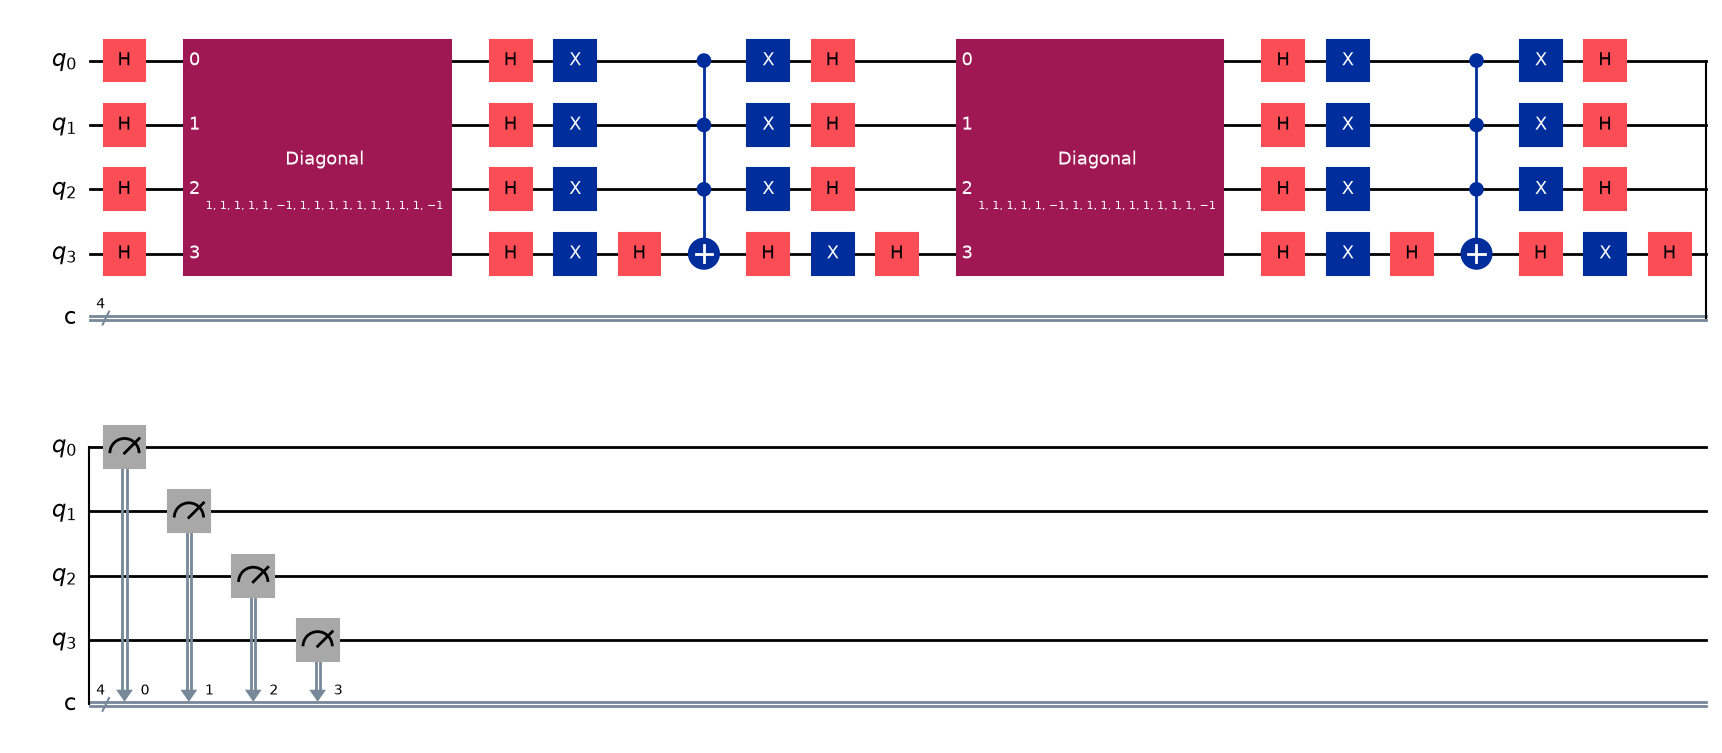

In [14]:

print("=== GROVER CIRCUIT DIAGNOSTICS ===")

print("Circuit depth:", grover_circuit.depth())
print("Circuit operations:", grover_circuit.count_ops())

print("\nCircuit parameters:")
print(grover_circuit.parameters)

print("\nCircuit drawing:")
display(grover_circuit.draw(output="mpl"))


In [15]:

print("=== CORRECTED GROVER SUCCESS PROBABILITY ===")

matching_bitstrings = {
    format(value, f"0{n_bits}b")
    for value in matching_inputs
}

matching_shots = sum(
    count
    for bitstring, count in counts.items()
    if bitstring.replace(" ", "") in matching_bitstrings
)

total_shots = sum(counts.values())
success_probability = matching_shots / total_shots

print("Matching inputs:", matching_inputs)
print("Matching bitstrings:", matching_bitstrings)
print("Total measured shots:", total_shots)
print("Matching measurements:", matching_shots)
print(f"Success probability: {success_probability:.4f}")
print(f"Success percentage: {success_probability * 100:.2f}%")


=== CORRECTED GROVER SUCCESS PROBABILITY ===
Matching inputs: [5, 15]
Matching bitstrings: {'0101', '1111'}
Total measured shots: 4096
Matching measurements: 3862
Success probability: 0.9429
Success percentage: 94.29%


### Experiment 1: Classical vs. Grover Search

**Configuration**
- Input size: 4 bits
- Total search space: 16 inputs
- Target hash: 5
- Matching inputs: 5 and 15
- Number of matching inputs: 2

**Grover simulation**
- Grover iterations: 2
- Number of shots: 4,096
- Successful measurements: 3,862
- Experimental success probability: 94.29%
- Theoretical success probability: 94.53%

**Observation**

The measured success probability was approximately 94.29%, compared with the theoretical prediction of 94.53%. The small difference is consistent with finite-shot sampling variation. This experiment demonstrates probability amplification for the selected toy-hash target in the simulated Grover search.

In [16]:

import math
import pandas as pd
from IPython.display import display

# Use results from our existing experiment
total_inputs = 2 ** n_bits
number_of_matches = len(matching_inputs)

# Theoretical Grover values
theta = math.asin(math.sqrt(number_of_matches / total_inputs))
optimal_iterations = round(math.pi / (4 * theta) - 0.5)

theoretical_probability = math.sin(
    (2 * optimal_iterations + 1) * theta
) ** 2

# Classical search effort for our current implementation:
# it checks every entry in hash_map to find all matching inputs.
classical_hash_evaluations = len(hash_map)

# Experimental Grover result from the corrected calculation
experimental_probability = success_probability

comparison = pd.DataFrame([
    {
        "Metric": "Total possible inputs",
        "Classical search": total_inputs,
        "Grover search": total_inputs
    },
    {
        "Metric": "Matching inputs",
        "Classical search": number_of_matches,
        "Grover search": number_of_matches
    },
    {
        "Metric": "Search method",
        "Classical search": "Evaluate hash map entries",
        "Grover search": "Oracle + diffusion"
    },
    {
        "Metric": "Classical hash evaluations / Grover iterations",
        "Classical search": classical_hash_evaluations,
        "Grover search": optimal_iterations
    },
    {
        "Metric": "Theoretical success probability",
        "Classical search": "Not applicable to exhaustive enumeration",
        "Grover search": f"{theoretical_probability * 100:.2f}%"
    },
    {
        "Metric": "Experimental Grover success probability",
        "Classical search": "Not applicable",
        "Grover search": f"{experimental_probability * 100:.2f}%"
    }
])

print("=== CLASSICAL VS QUANTUM COMPARISON ===")
display(comparison)


=== CLASSICAL VS QUANTUM COMPARISON ===


,Metric,Classical search,Grover search
0,Total possible inputs,16,16
1,Matching inputs,2,2
2,Search method,Evaluate hash map entries,Oracle + diffusion
3,Classical hash evaluations / Grover iterations,16,2
4,Theoretical success probability,Not applicable to exhaustive enumeration,94.53%
5,Experimental Grover success probability,Not applicable,94.29%


In [17]:

import csv
from pathlib import Path
import math

# Experiment configuration
total_inputs = 2 ** n_bits
number_of_matches = len(matching_inputs)
shots_used = sum(counts.values())

# Theoretical Grover success probability
theta = math.asin(
    math.sqrt(number_of_matches / total_inputs)
)

theoretical_probability = (
    math.sin((2 * optimal_iterations + 1) * theta) ** 2
)

# Experimental Grover success probability
experimental_probability = matching_shots / shots_used

# Create results folder if it doesn't exist
results_dir = Path("results")
results_dir.mkdir(parents=True, exist_ok=True)

csv_path = results_dir / "classical_vs_quantum_results.csv"

# One row for this experiment
experiment = {
    "input_bits": n_bits,
    "total_possible_inputs": total_inputs,
    "target_hash": target_hash,
    "matching_inputs": str(matching_inputs),
    "number_of_matching_inputs": number_of_matches,
    "classical_exhaustive_scan_entries": total_inputs,
    "grover_iterations": optimal_iterations,
    "shots": shots_used,
    "successful_measurements": matching_shots,
    "theoretical_success_probability": round(
        theoretical_probability, 6
    ),
    "experimental_success_probability": round(
        experimental_probability, 6
    ),
}

# Append the experiment without overwriting earlier results
file_exists = csv_path.exists()

with csv_path.open("a", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(
        file,
        fieldnames=experiment.keys()
    )

    if not file_exists or csv_path.stat().st_size == 0:
        writer.writeheader()

    writer.writerow(experiment)

print("=== EXPERIMENT SAVED ===")
print("File:", csv_path.resolve())
print("Input bits:", n_bits)
print("Matching inputs:", matching_inputs)
print(f"Theoretical success: {theoretical_probability * 100:.2f}%")
print(f"Experimental success: {experimental_probability * 100:.2f}%")
print("CSV file exists:", csv_path.exists())


=== EXPERIMENT SAVED ===
File: D:\quantum-project\notebooks\results\classical_vs_quantum_results.csv
Input bits: 4
Matching inputs: [5, 15]
Theoretical success: 94.53%
Experimental success: 94.29%
CSV file exists: True


In [28]:

import math
import csv
from pathlib import Path
import pandas as pd

from qiskit import transpile
from qiskit_aer import AerSimulator

from src.hash_functions.toy_hash import create_toy_hash_system
from src.classical_attack.preimage_search import classical_preimage_search
from src.quantum_grover.grover_search import create_grover_circuit

# Experiment settings
input_sizes = [2, 3, 4, 5, 6]
m_bits = 4
shots = 4096

simulator = AerSimulator()
experiment_rows = []

for bits in input_sizes:
    print(f"\nRunning experiment for {bits}-bit inputs...")

    hash_map_test = create_toy_hash_system(bits, m_bits)

    # Use input 0 as the target for each experiment
    target_input = 0
    target_hash_test = hash_map_test[target_input]

    matching_test = classical_preimage_search(
        hash_map_test, target_hash_test
    )

    N = 2 ** bits
    M = len(matching_test)

    theta = math.asin(math.sqrt(M / N))
    optimal_iterations = max(
        0, round(math.pi / (4 * theta) - 0.5)
    )

    theoretical_probability = math.sin(
        (2 * optimal_iterations + 1) * theta
    ) ** 2

    circuit = create_grover_circuit(
        hash_map=hash_map_test,
        target_hash=target_hash_test,
        n_bits=bits,
        iterations=optimal_iterations
    )

    compiled = transpile(circuit, simulator)
    result = simulator.run(compiled, shots=shots).result()
    counts_test = result.get_counts()

    matching_bitstrings = {
        format(value, f"0{bits}b")
        for value in matching_test
    }

    successful_shots = sum(
        count
        for bitstring, count in counts_test.items()
        if bitstring.replace(" ", "") in matching_bitstrings
    )

    experimental_probability = successful_shots / shots

    experiment_rows.append({
        "Input bits": bits,
        "Total inputs": N,
        "Hash bits": m_bits,
        "Target input": target_input,
        "Target hash": target_hash_test,
        "Matching inputs": str(matching_test),
        "Number of matches": M,
        "Grover iterations": optimal_iterations,
        "Shots": shots,
        "Successful shots": successful_shots,
        "Theoretical success (%)": round(
            theoretical_probability * 100, 2
        ),
        "Experimental success (%)": round(
            experimental_probability * 100, 2
        )
    })

# Arrange results in a readable table
results_df = pd.DataFrame(experiment_rows)

print("\n=== GROVER SCALING EXPERIMENT RESULTS ===")
display(results_df)

# Save to the existing scaling-results CSV
output_path = Path("results") / "grover_scaling_experiments.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)
results_df.to_csv(output_path, index=False)

print("\nSaved CSV:", output_path.resolve())
print("Experiment rows:", len(results_df))



Running experiment for 2-bit inputs...

--- Toy Hash System Configuration ---
Input Bit Size (n): 2 (Total inputs: 4)
Hash Output Size (m): 4 bits
-------------------------------------------------------
Input (Binary)   | Input (Dec)  | Hash Output (Binary)
-------------------------------------------------------
|00>           | 0            | |0000>
|01>           | 1            | |0001>
|10>           | 2            | |0010>
|11>           | 3            | |1001>
-------------------------------------------------------

Running experiment for 3-bit inputs...

--- Toy Hash System Configuration ---
Input Bit Size (n): 3 (Total inputs: 8)
Hash Output Size (m): 4 bits
-------------------------------------------------------
Input (Binary)   | Input (Dec)  | Hash Output (Binary)
-------------------------------------------------------
|000>           | 0            | |0000>
|001>           | 1            | |0001>
|010>           | 2            | |0010>
|011>           | 3            | |0011

,Input bits,Total inputs,Hash bits,Target input,Target hash,Matching inputs,Number of matches,Grover iterations,Shots,Successful shots,Theoretical success (%),Experimental success (%)
0,2,4,4,0,0,[0],1,1,4096,4096,100.00,100.00
1,3,8,4,0,0,[0],1,2,4096,3889,94.53,94.95
2,4,16,4,0,0,[0],1,3,4096,3946,96.13,96.34
3,5,32,4,0,0,"[0, 27]",2,3,4096,3934,96.13,96.04
4,6,64,4,0,0,"[0, 17, 34, 57]",4,3,4096,3919,96.13,95.68



Saved CSV: D:\quantum-project\notebooks\results\grover_scaling_experiments.csv
Experiment rows: 5


In [29]:

print("Input sizes received:", input_sizes)
print("Number of input sizes:", len(input_sizes))
print("Experiment rows generated:", len(experiment_rows))


Input sizes received: [2, 3, 4, 5, 6]
Number of input sizes: 5
Experiment rows generated: 5


In [30]:

import pandas as pd
from pathlib import Path

csv_path = Path("results") / "grover_scaling_experiments.csv"

results_df = pd.read_csv(csv_path)

print("=== SCALING EXPERIMENT VERIFICATION ===")
print("CSV file:", csv_path.resolve())
print("Number of experiment rows:", len(results_df))

display(results_df)


=== SCALING EXPERIMENT VERIFICATION ===
CSV file: D:\quantum-project\notebooks\results\grover_scaling_experiments.csv
Number of experiment rows: 5


,Input bits,Total inputs,Hash bits,Target input,Target hash,Matching inputs,Number of matches,Grover iterations,Shots,Successful shots,Theoretical success (%),Experimental success (%)
0,2,4,4,0,0,[0],1,1,4096,4096,100.00,100.00
1,3,8,4,0,0,[0],1,2,4096,3889,94.53,94.95
2,4,16,4,0,0,[0],1,3,4096,3946,96.13,96.34
3,5,32,4,0,0,"[0, 27]",2,3,4096,3934,96.13,96.04
4,6,64,4,0,0,"[0, 17, 34, 57]",4,3,4096,3919,96.13,95.68


In [31]:

import math

print("=== GROVER ITERATION VERIFICATION ===")

for _, row in results_df.iterrows():
    N = int(row["Total inputs"])
    M = int(row["Number of matches"])

    theta = math.asin(math.sqrt(M / N))
    estimated_iterations = max(
        0, round(math.pi / (4 * theta) - 0.5)
    )

    print(
        f'{int(row["Input bits"])} bits | '
        f'N={N} | M={M} | '
        f'Recorded={int(row["Grover iterations"])} | '
        f'Estimated={estimated_iterations}'
    )


=== GROVER ITERATION VERIFICATION ===
2 bits | N=4 | M=1 | Recorded=1 | Estimated=1
3 bits | N=8 | M=1 | Recorded=2 | Estimated=2
4 bits | N=16 | M=1 | Recorded=3 | Estimated=3
5 bits | N=32 | M=2 | Recorded=3 | Estimated=3
6 bits | N=64 | M=4 | Recorded=3 | Estimated=3


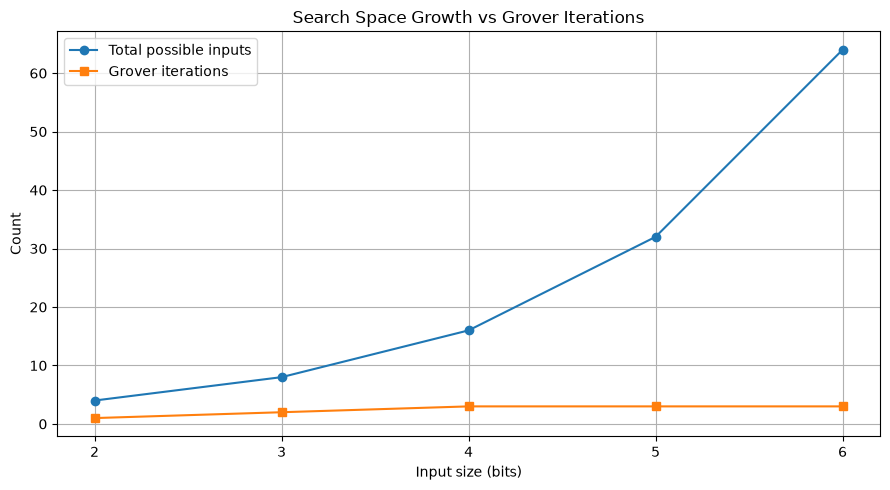

In [32]:

import matplotlib.pyplot as plt

# Sort results by input size
plot_df = results_df.sort_values("Input bits")

plt.figure(figsize=(9, 5))

plt.plot(
    plot_df["Input bits"],
    plot_df["Total inputs"],
    marker="o",
    label="Total possible inputs"
)

plt.plot(
    plot_df["Input bits"],
    plot_df["Grover iterations"],
    marker="s",
    label="Grover iterations"
)

plt.xlabel("Input size (bits)")
plt.ylabel("Count")
plt.title("Search Space Growth vs Grover Iterations")
plt.xticks(plot_df["Input bits"])
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [33]:

import pandas as pd

comparison_df = results_df[
    [
        "Input bits",
        "Total inputs",
        "Number of matches",
        "Grover iterations",
        "Theoretical success (%)",
        "Experimental success (%)"
    ]
].copy()

# Classical exhaustive-search upper bound
comparison_df["Classical worst-case evaluations"] = (
    comparison_df["Total inputs"]
)

# Idealized Grover oracle-query count
comparison_df["Grover oracle queries"] = (
    comparison_df["Grover iterations"]
)

comparison_df = comparison_df[
    [
        "Input bits",
        "Total inputs",
        "Number of matches",
        "Classical worst-case evaluations",
        "Grover oracle queries",
        "Theoretical success (%)",
        "Experimental success (%)"
    ]
]

print("=== CLASSICAL VS GROVER: SCALING COMPARISON ===")
display(comparison_df)


=== CLASSICAL VS GROVER: SCALING COMPARISON ===


,Input bits,Total inputs,Number of matches,Classical worst-case evaluations,Grover oracle queries,Theoretical success (%),Experimental success (%)
0,2,4,1,4,1,100.00,100.00
1,3,8,1,8,2,94.53,94.95
2,4,16,1,16,3,96.13,96.34
3,5,32,2,32,3,96.13,96.04
4,6,64,4,64,3,96.13,95.68


In [34]:

print("=== FINAL DATA CONSISTENCY CHECK ===")

for _, row in results_df.iterrows():
    bits = int(row["Input bits"])
    N = int(row["Total inputs"])
    M = int(row["Number of matches"])
    r = int(row["Grover iterations"])

    theta = math.asin(math.sqrt(M / N))
    calculated_probability = (
        math.sin((2 * r + 1) * theta) ** 2 * 100
    )

    recorded_probability = float(
        row["Theoretical success (%)"]
    )

    print(
        f"{bits}-bit input | "
        f"iterations={r} | "
        f"recorded={recorded_probability:.2f}% | "
        f"calculated={calculated_probability:.2f}%"
    )


=== FINAL DATA CONSISTENCY CHECK ===
2-bit input | iterations=1 | recorded=100.00% | calculated=100.00%
3-bit input | iterations=2 | recorded=94.53% | calculated=94.53%
4-bit input | iterations=3 | recorded=96.13% | calculated=96.13%
5-bit input | iterations=3 | recorded=96.13% | calculated=96.13%
6-bit input | iterations=3 | recorded=96.13% | calculated=96.13%


In [35]:

import math

# Experiment configuration
n_bits = int(input("Enter number of input bits (2-8): "))

if not 2 <= n_bits <= 8:
    raise ValueError("Input bits must be between 2 and 8.")

# Total possible inputs
N = 2 ** n_bits

print(f"\nInput bits: {n_bits}")
print(f"Total possible inputs (N): {N}")
print("\nTheoretical Grover success probability")
print("-" * 55)

# Test different numbers of matching inputs
matching_inputs_list = sorted(set([1, 2, N // 4, N // 2]))

for M in matching_inputs_list:
    if M < 1 or M > N:
        continue

    theta = math.asin(math.sqrt(M / N))

    # Optimal iteration estimate
    if M == N:
        iterations = 0
    else:
        iterations = max(
            0,
            round((math.pi / (4 * theta)) - 0.5)
        )

    # Theoretical probability after selected iterations
    probability = math.sin(
        (2 * iterations + 1) * theta
    ) ** 2

    print(f"\nMatching inputs (M): {M}")
    print(f"Initial success probability: {M / N:.4f}")
    print(f"Selected Grover iterations: {iterations}")
    print(f"Theoretical success probability: {probability:.4f}")
    print(f"Theoretical success percentage: {probability * 100:.2f}%")



Input bits: 3
Total possible inputs (N): 8

Theoretical Grover success probability
-------------------------------------------------------

Matching inputs (M): 1
Initial success probability: 0.1250
Selected Grover iterations: 2
Theoretical success probability: 0.9453
Theoretical success percentage: 94.53%

Matching inputs (M): 2
Initial success probability: 0.2500
Selected Grover iterations: 1
Theoretical success probability: 1.0000
Theoretical success percentage: 100.00%

Matching inputs (M): 4
Initial success probability: 0.5000
Selected Grover iterations: 0
Theoretical success probability: 0.5000
Theoretical success percentage: 50.00%


In [36]:

import math
import pandas as pd

# Reuse N and n_bits from the previous cell
results = []

for M in range(1, N + 1):
    theta = math.asin(math.sqrt(M / N))

    if M == N:
        iterations = 0
    else:
        iterations = max(
            0,
            round(math.pi / (4 * theta) - 0.5)
        )

    probability = math.sin(
        (2 * iterations + 1) * theta
    ) ** 2

    results.append({
        "Input Bits": n_bits,
        "Total Inputs (N)": N,
        "Matching Inputs (M)": M,
        "Initial Probability (%)": round(M / N * 100, 2),
        "Grover Iterations": iterations,
        "Final Probability (%)": round(probability * 100, 2)
    })

matching_results = pd.DataFrame(results)

display(matching_results)


,Input Bits,Total Inputs (N),Matching Inputs (M),Initial Probability (%),Grover Iterations,Final Probability (%)
0,3,8,1,12.5,2,94.53
1,3,8,2,25.0,1,100.00
2,3,8,3,37.5,1,84.38
3,3,8,4,50.0,0,50.00
4,3,8,5,62.5,0,62.50
5,3,8,6,75.0,0,75.00
6,3,8,7,87.5,0,87.50
7,3,8,8,100.0,0,100.00


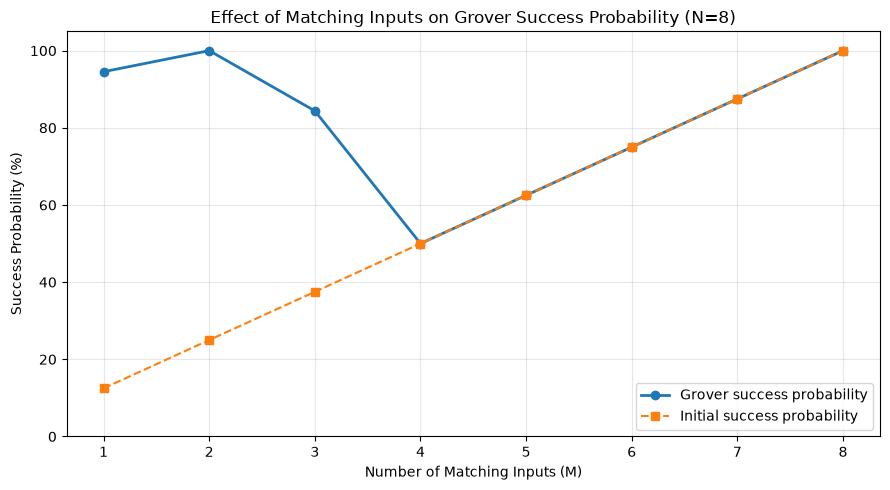

In [37]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    matching_results["Matching Inputs (M)"],
    matching_results["Final Probability (%)"],
    marker="o",
    linewidth=2,
    label="Grover success probability"
)

plt.plot(
    matching_results["Matching Inputs (M)"],
    matching_results["Initial Probability (%)"],
    marker="s",
    linestyle="--",
    label="Initial success probability"
)

plt.xlabel("Number of Matching Inputs (M)")
plt.ylabel("Success Probability (%)")
plt.title(
    f"Effect of Matching Inputs on Grover Success Probability (N={N})"
)

plt.xticks(range(1, N + 1))
plt.ylim(0, 105)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()
